# Presión fiscal: impuestos y cotizaciones sobre el PIB

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "presion-fiscal"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Presión fiscal: impuestos y cotizaciones sobre el PIB"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La *presión fiscal*: lo que ingresan las administraciones públicas (en España, el Estado, las comunidades autónomas, las entidades locales y la Seguridad Social) por impuestos y cotizaciones sociales obligatorias, en porcentaje del PIB. En los países de la UE incluye también lo que se recauda para las instituciones europeas, como los aranceles.

**Cómo se lee.** Un valor de 37 significa que lo recaudado en impuestos y cotizaciones equivale al 37 % del PIB de ese año.

**Limitaciones.**
- Mide lo recaudado, no los tipos impositivos ni lo que paga cada contribuyente: la ratio cambia también con el ciclo económico y con el peso en la economía de las rentas y el consumo que se gravan.
- Solo cuenta los pagos obligatorios a las administraciones públicas: las aportaciones a seguros o planes de pensiones privados quedan fuera aunque sean obligatorias, lo que afecta a la comparación entre países que financian de distinta forma su protección social.
- La media de la OCDE es una media simple de los países, sin ponderar por su tamaño; en los primeros años solo incluye los países con dato, y la del último año es una estimación de la OCDE (ver notas).
- Las series de España y Canadá de la OCDE cambian de criterio contable a mitad del periodo, de caja a devengo (ver notas).
- La serie de la UE-27 empieza más tarde porque Eurostat no publica el agregado en los años anteriores.

## 2. Descarga

- **España, OCDE, EE. UU. y Canadá:** OCDE, *Revenue Statistics* (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0), ingresos fiscales (`TAX_REV`) de las administraciones públicas (`S13`), total `_T` (código de ingreso `TOTALTAX`, *Total tax revenue*), en `PT_B1GQ` (% del PIB). La media de la OCDE es el área `OECD_REP` (*OECD average country*); el área `OECD` no tiene datos en este dataflow.
- **UE-27:** Eurostat `gov_10a_taxag`, sector `S13_S212` (administraciones públicas e instituciones de la UE), unidad `PC_GDP`, partida `D2_D5_D91_D61_M_D611V_D612_M_M_D613V_D614_M_D995` (impuestos y cotizaciones sociales obligatorias, sin las imputadas ni las voluntarias, menos los importes de cobro improbable), agregado `EU27_2020`.

La OCDE publica varios totales en este dataflow: `_T` es el de sus cifras titulares y el único con media OCDE en todos los años; los demás son los mismos ingresos en caja (`T_AA`) o en devengo (`T_AB`), en términos brutos o netos (`T_GROSS`, `T_NET`) o con los agregados de la contabilidad nacional (`T_AI`, `T_AK`). La sección 3 los compara en el último año.

Para las comprobaciones de la sección 3 (no se publican) se descargan también: todos los países de *Revenue Statistics*, los totales alternativos, España en Eurostat en millones de euros con dos variantes de la partida y el PIB (`nama_10_gdp`), la ratio con cotizaciones imputadas de la UE-27 y la última versión publicada del dataflow.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data


import io
import xml.etree.ElementTree as ET

import requests

from lib import eurostat, oecd
from lib._http import pedir
from lib.tipos import FuenteMeta

# OCDE, Revenue Statistics. La versión del dataflow cambia con las ediciones y las antiguas dejan de
# actualizarse: la sección 3 comprueba que esta sea la última publicada.
DATAFLOW = "OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0"
# Clave: REF_AREA.MEASURE.SECTOR.STANDARD_REVENUE.CTRY_SPECIFIC_REVENUE.UNIT_MEASURE.FREQ
#   TAX_REV: ingresos fiscales · S13: administraciones públicas · _T: total (TOTALTAX)
#   _T: sin desglose nacional · PT_B1GQ: % del PIB · A: anual
CLAVE = "{AREA}.TAX_REV.S13._T._T.PT_B1GQ.A"
# OECD_REP («OECD average country») es la media de la OCDE que publica Revenue Statistics
AREAS = {"ESP": "espana", "OECD_REP": "ocde", "USA": "eeuu", "CAN": "canada"}

# Eurostat, gov_10a_taxag: impuestos y cotizaciones sociales obligatorias (sin imputadas ni voluntarias), menos
# los importes de cobro improbable (D995), de las administraciones públicas y las instituciones de la UE
FILTROS_UE = {
    "freq": "A",
    "unit": "PC_GDP",
    "sector": "S13_S212",
    "na_item": "D2_D5_D91_D61_M_D611V_D612_M_M_D613V_D614_M_D995",
}
# Solo comprobaciones: la variante con las cotizaciones voluntarias y la que incluye también las imputadas
ITEM_CON_VOLUNTARIAS = "D2_D5_D91_D61_M_D612_M_D614_M_D995"
ITEM_CON_IMPUTADAS = "D2_D5_D91_D61_M_D995"


def descargar():
    """Devuelve (DataFrame `serie, periodo, valor`, lista de FuenteMeta)."""
    ocde, f_ocde = oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)
    ue, f_ue = eurostat.get("gov_10a_taxag", FILTROS_UE, geos={"EU27_2020": "ue27"}, desde=DESDE)
    return pd.concat([ocde, ue], ignore_index=True), [*f_ocde, *f_ue]


def sdmx_ocde(clave):
    """Solo para comprobar: SDMX-CSV de Revenue Statistics tal cual, para una clave sin marcador de área."""
    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW}/{clave}", {"startPeriod": str(DESDE)},
        error_cls=oecd.OecdError, etiqueta="comprobación", mensaje=lambda r: r.text[:200],
        headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text))


def ultima_version():
    """Versión más reciente del dataflow publicada por la OCDE."""
    agencia, flujo, _ = DATAFLOW.split(",")
    url = oecd.BASE.removesuffix("/data") + f"/dataflow/{agencia}/{flujo}/latest"
    r = pedir(
        requests.Session(), url, None, error_cls=oecd.OecdError, etiqueta="versión",
        mensaje=lambda r: r.text[:200],
    )
    ns = {"s": "http://www.sdmx.org/resources/sdmxml/schemas/v2_1/structure"}
    return ET.fromstring(r.content).find(".//s:Dataflow", ns).get("version")


df, fuentes = descargar()
version_ultima = ultima_version()
# Todos los países con el total publicado, para ver con cuántos se calcula la media OCDE cada año
todos = sdmx_ocde(".TAX_REV.S13._T._T.PT_B1GQ.A")
# Totales alternativos de las series publicadas: caja, devengo, bruto, neto y contabilidad nacional
totales = sdmx_ocde("+".join(AREAS) + ".TAX_REV.S13._T+T_AA+T_AB+T_GROSS+T_NET+T_AI+T_AK._T.PT_B1GQ.A")
# España en Eurostat, en millones de euros con las dos variantes de la partida, y el PIB
es_eurostat = {}
for item in (FILTROS_UE["na_item"], ITEM_CON_VOLUNTARIAS):
    d, _ = eurostat.get(
        "gov_10a_taxag", {**FILTROS_UE, "unit": "MIO_EUR", "na_item": item}, geos={"ES": "espana"}, desde=DESDE
    )
    es_eurostat[item] = d.set_index("periodo")["valor"]
pib_es, _ = eurostat.get(
    "nama_10_gdp", {"freq": "A", "unit": "CP_MEUR", "na_item": "B1GQ"}, geos={"ES": "espana"}, desde=DESDE
)
# UE-27 con las cotizaciones imputadas
ue_imputadas, _ = eurostat.get(
    "gov_10a_taxag", {**FILTROS_UE, "na_item": ITEM_CON_IMPUTADAS}, geos={"EU27_2020": "ue27"}, desde=DESDE
)

## 3. Transformación

Las dos fuentes ya publican el porcentaje del PIB: no hay deflactor, cambio de unidades ni enlace de series. Se combinan las cuatro series de la OCDE con la de la UE-27 de Eurostat y se completa el código de cada fuente.

In [ ]:
assert df["valor"].between(10, 60).all(), "presión fiscal fuera de un rango plausible (% del PIB)"
_, flujo, version = DATAFLOW.split(",")
CODIGO_OCDE = f"{flujo} (Revenue Statistics, versión {version}): TAX_REV, S13, _T (TOTALTAX), PT_B1GQ"
CODIGO_UE = f"gov_10a_taxag: {FILTROS_UE['sector']}, {FILTROS_UE['unit']}, {FILTROS_UE['na_item']}"
def codigo(f):
    """Código de la fuente de cada serie; en la media OCDE, con su área."""
    if f.organismo != oecd.ORGANISMO:
        return CODIGO_UE
    return CODIGO_OCDE + ("; área OECD_REP" if f.serie == "ocde" else "")


fuentes = [FuenteMeta(f.serie, f.organismo, codigo(f), f.url, f.fecha_consulta) for f in fuentes]
df.pivot(index="periodo", columns="serie", values="valor").round(2).tail(10)

serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2015,32.82,26.09,33.54,32.92,39.7
2016,33.26,25.71,33.32,33.56,39.8
2017,33.04,26.46,33.63,33.32,39.9
2018,33.48,24.82,34.41,33.42,40.0
2019,33.08,24.96,34.44,33.35,39.9
2020,34.45,25.51,36.51,33.46,40.0
2021,34.80,26.83,37.41,34.02,40.2
2022,33.88,28.05,36.75,33.96,39.7
2023,34.79,25.63,36.41,33.73,38.9


### Comprobaciones

No cambian los datos publicados:
1. Que la versión fijada del dataflow sea la última que publica la OCDE.
2. Qué total publica la OCDE en cada caso: el último año, todos los totales de las series publicadas.
3. Con cuántos países se calcula la media OCDE cada año, cuánto mueve la media la entrada de países en el cálculo y cómo se obtiene la del último año.
4. En qué año pasa cada serie de la OCDE de la recaudación en caja a la de devengo.
5. España en las dos fuentes: la OCDE frente a Eurostat con la partida de la UE-27 y con la variante que incluye las cotizaciones voluntarias, ambas calculadas en millones de euros sobre el PIB para no depender del redondeo a un decimal.
6. La UE-27 con y sin las cotizaciones imputadas.

In [ ]:
# 1) Versión del dataflow
if version_ultima != version:
    print(f"AVISO: la OCDE publica la versión {version_ultima} del dataflow y aquí se usa la {version}: actualiza DATAFLOW.")
else:
    print(f"La versión usada del dataflow ({version}) es la última publicada por la OCDE.")

# 2) Totales publicados por la OCDE en el último año (la gráfica usa _T)
tot = totales.pivot_table(index=["REF_AREA", "TIME_PERIOD"], columns="STANDARD_REVENUE", values="OBS_VALUE")
ultimo_ocde = int(df.loc[df["serie"] != "ue27", "periodo"].max())
tot.xs(ultimo_ocde, level="TIME_PERIOD").round(2)

La versión usada del dataflow (2.0) es la última publicada por la OCDE.


STANDARD_REVENUE,T_AA,T_AB,T_AI,T_AK,T_GROSS,T_NET,_T
REF_AREA,,,,,,,
CAN,0.0,34.90,34.99,34.99,34.90,34.90,34.90
ESP,36.2,36.68,36.83,37.27,36.68,36.68,36.68
OECD_REP,NaN,NaN,NaN,NaN,NaN,NaN,34.06
USA,NaN,NaN,26.12,26.16,25.62,25.62,25.62


In [ ]:
# 3) Media OCDE: países con dato, efecto de la entrada de países y último año
NOMBRES_PAIS = {
    "AUS": "Australia", "AUT": "Austria", "BEL": "Bélgica", "CAN": "Canadá", "CHE": "Suiza", "CHL": "Chile",
    "COL": "Colombia", "CRI": "Costa Rica", "CZE": "Chequia", "DEU": "Alemania", "DNK": "Dinamarca",
    "ESP": "España", "EST": "Estonia", "FIN": "Finlandia", "FRA": "Francia", "GBR": "Reino Unido",
    "GRC": "Grecia", "HUN": "Hungría", "IRL": "Irlanda", "ISL": "Islandia", "ISR": "Israel", "ITA": "Italia",
    "JPN": "Japón", "KOR": "Corea del Sur", "LTU": "Lituania", "LUX": "Luxemburgo", "LVA": "Letonia",
    "MEX": "México", "NLD": "Países Bajos", "NOR": "Noruega", "NZL": "Nueva Zelanda", "POL": "Polonia",
    "PRT": "Portugal", "SVK": "Eslovaquia", "SVN": "Eslovenia", "SWE": "Suecia", "TUR": "Turquía",
    "USA": "Estados Unidos",
}
es_pais = todos["REF_AREA"].str.fullmatch(r"[A-Z]{3}")  # fuera los agregados (OECD_REP, FEDOECD, UNIOECD)
paises = todos[es_pais].pivot_table(index="TIME_PERIOD", columns="REF_AREA", values="OBS_VALUE")
media_ocde = todos[todos["REF_AREA"] == "OECD_REP"].set_index("TIME_PERIOD")["OBS_VALUE"]
n_paises = paises.notna().sum(axis=1)
n_miembros = paises.shape[1]
comp = pd.DataFrame({"países con dato": n_paises, "media simple": paises.mean(axis=1), "OECD_REP": media_ocde})
comp["diferencia"] = comp["media simple"] - comp["OECD_REP"]
anteriores = comp.index < ultimo_ocde
assert comp.loc[anteriores, "diferencia"].abs().max() < 0.001, "OECD_REP ya no es la media simple de los países con dato"
completos = n_paises[anteriores] == n_miembros
anio_completa = int(completos[~completos].index.max()) + 1  # desde este año, todos los miembros
assert completos.loc[anio_completa:].all()

# Años en que cambia el número de países: variación de la media publicada frente a la de los que ya tenían dato
filas = []
for a in n_paises.index[(n_paises.index > DESDE) & anteriores]:
    if n_paises[a] != n_paises[a - 1]:
        ambos = paises.columns[paises.loc[a].notna() & paises.loc[a - 1].notna()]
        filas.append({
            "año": a, "países antes": n_paises[a - 1], "países después": n_paises[a],
            "variación publicada": media_ocde[a] - media_ocde[a - 1],
            "variación de los que ya estaban": (paises.loc[a, ambos] - paises.loc[a - 1, ambos]).mean(),
        })
entradas = pd.DataFrame(filas).set_index("año")
entradas["efecto de la entrada"] = entradas["variación publicada"] - entradas["variación de los que ya estaban"]
mayor_entrada = entradas.loc[entradas["efecto de la entrada"].abs().idxmax()]
anio_mayor_entrada = int(entradas["efecto de la entrada"].abs().idxmax())
entran = [p for p in paises.columns if pd.notna(paises.loc[anio_mayor_entrada, p]) and pd.isna(paises.loc[anio_mayor_entrada - 1, p])]
print(f"Entran en {anio_mayor_entrada}: {', '.join(entran)}")

# Último año: la OCDE aplica a la media del año anterior la variación media de los países con dato
con_dato = paises.columns[paises.loc[ultimo_ocde].notna() & paises.loc[ultimo_ocde - 1].notna()]
faltan_ultimo = sorted(set(paises.columns) - set(paises.columns[paises.loc[ultimo_ocde].notna()]))
estimacion = media_ocde[ultimo_ocde - 1] + (paises.loc[ultimo_ocde, con_dato] - paises.loc[ultimo_ocde - 1, con_dato]).mean()
media_estimada = bool(faltan_ultimo) and abs(estimacion - media_ocde[ultimo_ocde]) < 0.01
print(f"Media OCDE: {n_paises[DESDE]} países en {DESDE}; los {n_miembros} miembros desde {anio_completa}.")
print(f"{ultimo_ocde}: faltan {', '.join(faltan_ultimo) or 'ninguno'}; media publicada {media_ocde[ultimo_ocde]:.3f}, "
      f"estimación con la variación media de {len(con_dato)} países {estimacion:.3f}")
entradas.round(3)

Entran en 1990: CHL, COL, CRI
Media OCDE: 24 países en 1976; los 38 miembros desde 1995.
2024: faltan AUS, JPN; media publicada 34.063, estimación con la variación media de 36 países 34.064


,países antes,países después,variación publicada,variación de los que ya estaban,efecto de la entrada
año,,,,,
1980,24,26,0.034,0.801,-0.767
1990,26,29,-1.506,0.104,-1.610
1991,29,31,0.431,-0.116,0.547
1993,31,32,0.380,0.233,0.147
1995,32,38,0.161,-0.251,0.412


In [ ]:
# 4) Recaudación en caja (T_AA) o en devengo (T_AB): año del cambio en cada serie de la OCDE
rupturas = {}
for area, serie in AREAS.items():
    if area not in tot.index.get_level_values("REF_AREA") or "T_AB" not in tot:
        continue
    t = tot.loc[area]
    if t["T_AB"].dropna().empty or area == "OECD_REP":  # la media no tiene un criterio propio
        continue
    a = int(t["T_AB"].first_valid_index())
    antes, despues = t.loc[t.index < a], t.loc[t.index >= a].dropna(subset=["T_AB"])
    assert ((antes["_T"] - antes["T_AA"]).abs() < 0.0005).all(), f"{area}: antes de {a} el total no es el de caja"
    assert ((despues["_T"] - despues["T_AB"]).abs() < 0.0005).all(), f"{area}: desde {a} el total no es el de devengo"
    rupturas[serie] = (a, t.loc[a, "T_AB"] - t.loc[a, "T_AA"])
print({s: (a, round(d, 3)) for s, (a, d) in rupturas.items()})

{'espana': (1995, np.float64(0.291)), 'canada': (1999, np.float64(0.52))}


In [ ]:
# 5) España: OCDE frente a Eurostat (millones de euros sobre el PIB)
pib = pib_es.set_index("periodo")["valor"]
espana = pd.DataFrame({
    "OCDE (gráfica)": df[df["serie"] == "espana"].set_index("periodo")["valor"],
    "Eurostat, partida de la UE-27": es_eurostat[FILTROS_UE["na_item"]] / pib * 100,
    "Eurostat, con voluntarias": es_eurostat[ITEM_CON_VOLUNTARIAS] / pib * 100,
}).dropna()
espana["diferencia"] = espana["Eurostat, partida de la UE-27"] - espana["OCDE (gráfica)"]
espana["diferencia con voluntarias"] = espana["Eurostat, con voluntarias"] - espana["OCDE (gráfica)"]
UMBRAL = 0.005  # puntos: por debajo, las dos fuentes coinciden con dos decimales
iguales = [int(a) for a in espana.index[espana["diferencia"].abs() < UMBRAL]]
distintos = espana.loc[espana["diferencia"].abs() >= UMBRAL, "diferencia"]
anio_dif_max = int(espana["diferencia"].abs().idxmax())
anio_dif_vol = int(espana["diferencia con voluntarias"].abs().idxmax())
print(f"Coinciden: {iguales}; diferencia máxima {espana.loc[anio_dif_max, 'diferencia']:.3f} ({anio_dif_max}); "
      f"con voluntarias, {espana.loc[anio_dif_vol, 'diferencia con voluntarias']:.3f} ({anio_dif_vol})")
espana.round(3)

Coinciden: [1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2024]; diferencia máxima 0.158 (2023); con voluntarias, 0.257 (2013)


,OCDE (gráfica),"Eurostat, partida de la UE-27","Eurostat, con voluntarias",diferencia,diferencia con voluntarias
periodo,,,,,
1995,31.319,31.319,31.355,0.000,0.036
1996,31.116,31.116,31.152,-0.000,0.036
1997,31.957,31.957,31.995,0.000,0.039
1998,32.774,32.774,32.825,0.000,0.051
1999,33.151,33.151,33.213,-0.000,0.063
2000,33.053,33.053,33.122,-0.000,0.069
2001,32.785,32.785,32.857,-0.000,0.072
2002,33.225,33.225,33.303,0.000,0.078
2003,33.066,33.101,33.184,0.036,0.118


In [ ]:
# 6) UE-27 con y sin las cotizaciones imputadas
ue = pd.DataFrame({
    "gráfica (obligatorias)": df[df["serie"] == "ue27"].set_index("periodo")["valor"],
    "con imputadas": ue_imputadas.set_index("periodo")["valor"],
})
ultimo_ue = int(ue["gráfica (obligatorias)"].last_valid_index())
ue.dropna().round(1).tail(6)

,gráfica (obligatorias),con imputadas
periodo,,
2019,39.9,41.0
2020,40.0,41.1
2021,40.2,41.2
2022,39.7,40.7
2023,38.9,39.9
2024,39.3,40.3


In [ ]:
def unir(xs):
    """«A», «A y B», «A, B y C»."""
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def tramos(anios):
    """[1995, 1996, 1997, 2024] → «1995-1997 y 2024»."""
    grupos = []
    for a in sorted(anios):
        if grupos and a == grupos[-1][-1] + 1:
            grupos[-1].append(a)
        else:
            grupos.append([a])
    return unir(f"{g[0]}-{g[-1]}" if len(g) > 1 else str(g[0]) for g in grupos)


def num(x, decimales=1):
    return estilos.formato_es(x, decimales)


def sube_baja(x, decimales=1):
    return "no cambia" if round(x, decimales) == 0 else f"{'sube' if x > 0 else 'baja'} {num(abs(x), decimales)} puntos"


NOMBRE = {"espana": "España", "canada": "Canadá", "eeuu": "EE. UU."}

NOTAS = [
    f"España, media OCDE, EE. UU. y Canadá: OCDE, Revenue Statistics ({flujo}, versión {version}), ingresos fiscales "
    "totales (TOTALTAX) de las administraciones públicas en porcentaje del PIB: impuestos de todos los niveles de "
    "gobierno y cotizaciones obligatorias a la seguridad social, incluidos en los países de la UE los que se "
    "recaudan para las instituciones europeas.",
    f"Media UE-27: Eurostat gov_10a_taxag ({FILTROS_UE['na_item']}, sector {FILTROS_UE['sector']}), impuestos y "
    "cotizaciones sociales obligatorias, sin las cotizaciones imputadas ni las voluntarias y descontados los importes "
    "de cobro improbable, de las administraciones públicas y las instituciones de la UE. Es la partida de Eurostat más "
    "próxima a la definición de la OCDE. Agregado de composición actual (EU27_2020); los años anteriores quedan sin "
    "dato porque Eurostat no publica el agregado.",
    f"Media OCDE: media simple, sin ponderar, de los países que hoy son miembros de la OCDE con dato en cada año "
    f"(área OECD_REP): {n_paises[DESDE]} países en {DESDE} y los {n_miembros} desde {anio_completa}. Hasta entonces, "
    f"la entrada de países en el cálculo mueve la media: en {anio_mayor_entrada}, al pasar de "
    f"{int(mayor_entrada['países antes'])} a {int(mayor_entrada['países después'])} países (entran "
    f"{unir(sorted(NOMBRES_PAIS.get(p, p) for p in entran))}), la media "
    f"{sube_baja(mayor_entrada['variación publicada'])}, mientras que la de los países que ya tenían dato "
    f"{sube_baja(mayor_entrada['variación de los que ya estaban'])}.",
]
if media_estimada:
    NOTAS.append(
        f"La media OCDE de {ultimo_ocde} es una estimación de la OCDE: aplica a la media de {ultimo_ocde - 1} la "
        f"variación media de los {len(con_dato)} países con dato en {ultimo_ocde} (faltan "
        f"{unir(NOMBRES_PAIS.get(p, p) for p in faltan_ultimo)})."
    )
if rupturas:
    cambios = [f"en {a} en {NOMBRE.get(s, s)}" for s, (a, _) in rupturas.items()]
    if all(d > 0 for _, d in rupturas.values()):
        efecto = "el dato en devengo supera al de caja en " + unir(
            f"{num(d)} puntos ({NOMBRE.get(s, s)})" for s, (_, d) in rupturas.items()
        )
    else:
        efecto = "la diferencia entre devengo y caja es de " + unir(
            f"{num(d)} puntos ({NOMBRE.get(s, s)})" for s, (_, d) in rupturas.items()
        )
    NOTAS.append(
        "Ruptura de serie: la OCDE pasa de contabilizar la recaudación en caja a hacerlo en devengo (el criterio de "
        f"la contabilidad nacional) {unir(cambios)}. Ese año, {efecto}."
    )
dif_max = num(abs(espana.loc[anio_dif_max, "diferencia"]), 2)
if (distintos > 0).all() or (distintos < 0).all():
    resto = f"es hasta {dif_max} puntos {'más alta' if (distintos > 0).all() else 'más baja'} ({anio_dif_max})"
else:
    resto = f"difiere hasta {dif_max} puntos ({anio_dif_max})"
coinciden = f"coincide con la de la OCDE en {tramos(iguales)} y en el resto de años {resto}" if iguales else resto
NOTAS.append(
    "España en las dos fuentes: la presión fiscal que resulta de Eurostat con la misma partida que la UE-27 "
    f"(calculada en millones de euros sobre el PIB) {coinciden}. Si se incluyen las "
    "cotizaciones sociales voluntarias, que la OCDE no cuenta como impuestos, la diferencia llega a "
    f"{num(abs(espana.loc[anio_dif_vol, 'diferencia con voluntarias']), 2)} puntos ({anio_dif_vol})."
)
NOTAS.append(
    f"La ratio de Eurostat que incluye también las cotizaciones sociales imputadas ({ITEM_CON_IMPUTADAS}), que es la "
    f"que destaca en sus estadísticas de ingresos fiscales, es más alta: en {ultimo_ue}, {num(ue.loc[ultimo_ue, 'con imputadas'])} % del "
    f"PIB en la UE-27, frente al {num(ue.loc[ultimo_ue, 'gráfica (obligatorias)'])} % de esta gráfica."
)
for n in NOTAS:
    print("-", n)

- España, media OCDE, EE. UU. y Canadá: OCDE, Revenue Statistics (DSD_REV_COMP_OECD@DF_RSOECD, versión 2.0), ingresos fiscales totales (TOTALTAX) de las administraciones públicas en porcentaje del PIB: impuestos de todos los niveles de gobierno y cotizaciones obligatorias a la seguridad social, incluidos en los países de la UE los que se recaudan para las instituciones europeas.
- Media UE-27: Eurostat gov_10a_taxag (D2_D5_D91_D61_M_D611V_D612_M_M_D613V_D614_M_D995, sector S13_S212), impuestos y cotizaciones sociales obligatorias, sin las cotizaciones imputadas ni las voluntarias y descontados los importes de cobro improbable, de las administraciones públicas y las instituciones de la UE. Es la partida de Eurostat más próxima a la definición de la OCDE. Agregado de composición actual (EU27_2020); los años anteriores quedan sin dato porque Eurostat no publica el agregado.
- Media OCDE: media simple, sin ponderar, de los países que hoy son miembros de la OCDE con dato en cada año (área O

## 4. Visualización

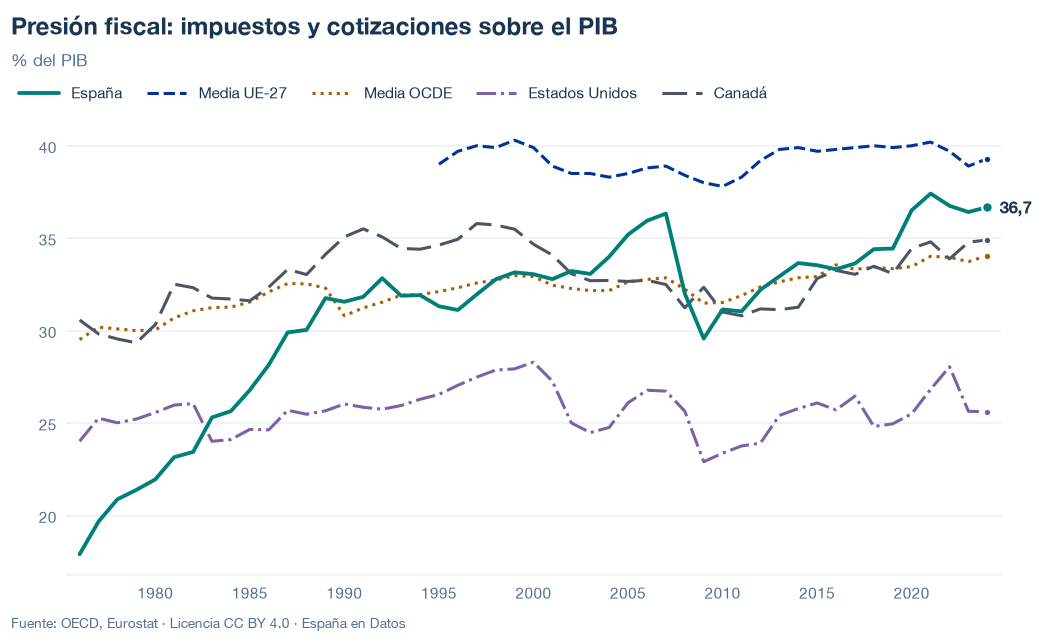

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/presion-fiscal.json y data/presion-fiscal.csv


## 6. Fuentes, notas y licencia

- OCDE, *Revenue Statistics* (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0): total `_T` (publicado) y totales `T_AA`, `T_AB`, `T_GROSS`, `T_NET`, `T_AI` y `T_AK` y todos los países (comprobaciones).
- Eurostat, `gov_10a_taxag` (publicado: UE-27; comprobaciones: España en millones de euros y la variante con cotizaciones imputadas) y `nama_10_gdp` (PIB de España, comprobaciones).

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.